In [4]:
import pandas as pd
import os

DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"

print("--- ФАЙЛ 1: БЕДНОСТЬ ---")
try:
    poverty = pd.read_excel(os.path.join(DATA_PATH, "poverty_percent.xls"), header=None, engine='xlrd')
    print(f"Размер: {poverty.shape}")
    display(poverty.head(10))
except Exception as e:
    print(f"Ошибка: {e}")

print("\n" + "="*50 + "\n")

print("--- ФАЙЛ 2: СОЦ-ДЕМОГРАФИЯ ---")
try:
    socdem = pd.read_excel(os.path.join(DATA_PATH, "poverty_socdem.xls"), header=None, engine='xlrd')
    print(f"Размер: {socdem.shape}")
    display(socdem.head(10))
except Exception as e:
    print(f"Ошибка: {e}")

--- ФАЙЛ 1: БЕДНОСТЬ ---
Размер: (179, 5)


,0,1,2,3,4
0,Численность населения с денежными доходами ниж...,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,Численность населения с денежными доходами ниж...
3,значение показателя за год,Российская Федерация,процент,2019.0,12.4
4,значение показателя за год,Российская Федерация,процент,2020.0,12.2
5,значение показателя за год,Белгородская область,процент,2019.0,7.8
6,значение показателя за год,Белгородская область,процент,2020.0,7.2
7,значение показателя за год,Брянская область,процент,2019.0,13.8
8,значение показателя за год,Брянская область,процент,2020.0,13.6
9,значение показателя за год,Владимирская область,процент,2019.0,12.7




--- ФАЙЛ 2: СОЦ-ДЕМОГРАФИЯ ---
Размер: (91, 5)


,0,1,2,3,4
0,Распределение малоимущего населения по социаль...,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,NaN,Все население,Дети в возрасте до 16 лет,Население старше трудоспособного возраста,Население трудоспособного возраста
3,Российская Федерация,100,39.8,6,54.2
4,Белгородская область,100,44.5,10.6,44.9
5,Брянская область,100,43.9,4.6,51.5
6,Владимирская область,100,35.3,7.9,56.8
7,Воронежская область,100,38.7,5,56.3
8,Ивановская область,100,35.6,9.2,55.2
9,Калужская область,100,42.6,6.8,50.5


In [38]:
import pandas as pd
import os

DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"

# ==========================================
# 1. ОЧИСТКА ФАЙЛА С БЕДНОСТЬЮ
# ==========================================
# Читаем, пропуская первые 3 строки (index 0,1,2), 
# и сразу задаем имена столбцам
poverty_clean = pd.read_excel(
    os.path.join(DATA_PATH, "poverty_percent.xls"), 
    skiprows=3,  # Пропускаем мусор сверху
    names=['temp', 'region', 'unit', 'year', 'poverty_percent'], # Задаем имена
    engine='xlrd'
)

# Удаляем ненужный столбец 'temp' и 'unit'
poverty_clean = poverty_clean[['region', 'year', 'poverty_percent']]

print("--- ОЧИЩЕННАЯ БЕДНОСТЬ ---")
print(f"Размер: {poverty_clean.shape}")
display(poverty_clean.head())
print(f"Уникальные годы: {poverty_clean['year'].unique()}")


# ==========================================
# 2. ОЧИСТКА ФАЙЛА С СОЦ-ДЕМОГРАФИЕЙ
# ==========================================
# Читаем, пропуская первые 2 строки, 
# а строку с заголовками (индекс 2) используем как названия столбцов
socdem_clean = pd.read_excel(
    os.path.join(DATA_PATH, "poverty_socdem.xls"),
    skiprows=2, # Пропускаем 2 строки, 3-я станет заголовком
    engine='xlrd'
)

# Переименуем первый столбец (там, где названия регионов)
socdem_clean = socdem_clean.rename(columns={socdem_clean.columns[0]: 'region'})

print("\n--- ОЧИЩЕННАЯ СОЦ-ДЕМОГРАФИЯ ---")
print(f"Размер: {socdem_clean.shape}")
display(socdem_clean.head())

--- ОЧИЩЕННАЯ БЕДНОСТЬ ---
Размер: (175, 3)


,region,year,poverty_percent
0,Российская Федерация,2020,12.2
1,Белгородская область,2019,7.8
2,Белгородская область,2020,7.2
3,Брянская область,2019,13.8
4,Брянская область,2020,13.6


Уникальные годы: [2020 2019]

--- ОЧИЩЕННАЯ СОЦ-ДЕМОГРАФИЯ ---
Размер: (88, 5)


,region,Все население,Дети в возрасте до 16 лет,Население старше трудоспособного возраста,Население трудоспособного возраста
0,Российская Федерация,100,39.8,6.0,54.2
1,Белгородская область,100,44.5,10.6,44.9
2,Брянская область,100,43.9,4.6,51.5
3,Владимирская область,100,35.3,7.9,56.8
4,Воронежская область,100,38.7,5.0,56.3


In [39]:
# Переименовываем столбцы для удобства
socdem_clean = socdem_clean.rename(columns={
    'Дети в возрасте до 16 лет': 'children_pct',
    'Население старше трудоспособного возраста': 'pensioners_pct',
    'Население трудоспособного возраста': 'working_age_pct',
    'Все население': 'total_population_pct'
})

# Выводим результат, чтобы проверить
display(socdem_clean.head())

,region,total_population_pct,children_pct,pensioners_pct,working_age_pct
0,Российская Федерация,100,39.8,6.0,54.2
1,Белгородская область,100,44.5,10.6,44.9
2,Брянская область,100,43.9,4.6,51.5
3,Владимирская область,100,35.3,7.9,56.8
4,Воронежская область,100,38.7,5.0,56.3


In [40]:
# Объединяем по столбцу 'region'
# how='left' означает, что мы берем все регионы из таблицы бедности, 
# и подтягиваем к ним данные по соц-демографии
merged_df = poverty_clean.merge(socdem_clean, on='region', how='left')

print(f"Размер объединенной таблицы: {merged_df.shape}")
display(merged_df.head(10))

Размер объединенной таблицы: (175, 7)


,region,year,poverty_percent,total_population_pct,children_pct,pensioners_pct,working_age_pct
0,Российская Федерация,2020,12.2,100.0,39.8,6.0,54.2
1,Белгородская область,2019,7.8,100.0,44.5,10.6,44.9
2,Белгородская область,2020,7.2,100.0,44.5,10.6,44.9
3,Брянская область,2019,13.8,100.0,43.9,4.6,51.5
4,Брянская область,2020,13.6,100.0,43.9,4.6,51.5
5,Владимирская область,2019,12.7,100.0,35.3,7.9,56.8
6,Владимирская область,2020,12.6,100.0,35.3,7.9,56.8
7,Воронежская область,2019,8.9,100.0,38.7,5.0,56.3
8,Воронежская область,2020,8.5,100.0,38.7,5.0,56.3
9,Ивановская область,2019,13.6,100.0,35.6,9.2,55.2


Матрица корреляций:


,poverty_percent,children_pct,pensioners_pct,working_age_pct
poverty_percent,1.000000,-0.133154,0.109096,0.070177
children_pct,-0.133154,1.000000,-0.318449,-0.830007
pensioners_pct,0.109096,-0.318449,1.000000,-0.264162
working_age_pct,0.070177,-0.830007,-0.264162,1.000000


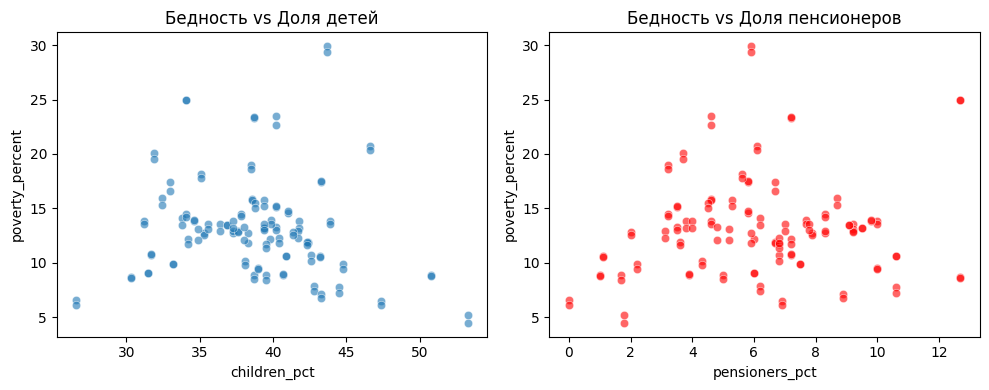

In [41]:
# Считаем корреляцию между бедностью и долей детей/пенсионеров
correlation = merged_df[['poverty_percent', 'children_pct', 'pensioners_pct', 'working_age_pct']].corr()

print("Матрица корреляций:")
display(correlation)

# Строим график рассеяния (scatter plot)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))

# График 1: Бедность vs Дети
plt.subplot(1, 2, 1)
sns.scatterplot(data=merged_df, x='children_pct', y='poverty_percent', alpha=0.6)
plt.title('Бедность vs Доля детей')

# График 2: Бедность vs Пенсионеры
plt.subplot(1, 2, 2)
sns.scatterplot(data=merged_df, x='pensioners_pct', y='poverty_percent', alpha=0.6, color='red')
plt.title('Бедность vs Доля пенсионеров')

plt.tight_layout()
plt.show()

In [42]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"

# Функция для быстрого просмотра структуры файла
def peek_file(filename):
    print(f"\n{'='*60}")
    print(f"ФАЙЛ: {filename}")
    print('='*60)
    
    try:
        # Читаем первый лист Excel
        df = pd.read_excel(os.path.join(DATA_PATH, filename))
        print(f"Размер: {df.shape}")
        
        # Выводим названия первых 15 столбцов
        print("\nНазвания столбцов (первые 15):")
        for col in df.columns[:15]:
            print(f" - {col}")
            
        print("\nПервые 3 строки:")
        display(df.head(3))
        
    except Exception as e:
        print(f"Ошибка: {e}")

# Смотрим файлы
peek_file("demography.xlsx")
peek_file("social_status.xlsx")
peek_file("paid_service.xlsx")


ФАЙЛ: demography.xlsx
Размер: (10560, 14)

Названия столбцов (первые 15):
 - section
 - indicator_code
 - indicator_name
 - subsection
 - object_name
 - object_level
 - object_oktmo
 - object_okato
 - year
 - indicator_value
 - indicator_unit
 - comment
 - source
 - version_date

Первые 3 строки:


,section,indicator_code,indicator_name,subsection,object_name,object_level,object_oktmo,object_okato,year,indicator_value,indicator_unit,comment,source,version_date
0,Миграция,Y477010001,Выбывшие из субъектов Российской Федерации в о...,В том числе в страны: Азербайджан,Алтайский край,Регион,1000000,1000000,2022,416.0,Человек,CD,Демографический ежегодник России 2023,v20260313
1,Миграция,Y477010001,Выбывшие из субъектов Российской Федерации в о...,В том числе в страны: Азербайджан,Амурская область,Регион,10000000,10000000,2022,119.0,Человек,CD,Демографический ежегодник России 2023,v20260313
2,Миграция,Y477010001,Выбывшие из субъектов Российской Федерации в о...,В том числе в страны: Азербайджан,Архангельская область (без автономного округа),Регион,11000000,11000000,2022,165.0,Человек,CD,Демографический ежегодник России 2023,v20260313



ФАЙЛ: social_status.xlsx
Размер: (103340, 14)

Названия столбцов (первые 15):
 - section
 - indicator_code
 - indicator_name
 - subsection
 - object_name
 - object_level
 - object_oktmo
 - object_okato
 - year
 - indicator_value
 - indicator_unit
 - comment
 - source
 - version_date

Первые 3 строки:


,section,indicator_code,indicator_name,subsection,object_name,object_level,object_oktmo,object_okato,year,indicator_value,indicator_unit,comment,source,version_date
0,Демографическая ситуация,Y477130020,Общие показатели демографического развития,"Миграционный прирост, на 10 000 человек населения",Алтайский край,Регион,1000000,1000000,2021,-61.702783,ND,Данные публикуются с учетом итогов ВПН-2020,Социальное положение и уровень жизни населения...,v20260313
1,Демографическая ситуация,Y477130020,Общие показатели демографического развития,"Миграционный прирост, на 10 000 человек населения",Алтайский край,Регион,1000000,1000000,2022,-36.300000,ND,Данные публикуются с учетом итогов ВПН-2020,Социальное положение и уровень жизни населения...,v20260313
2,Демографическая ситуация,Y477130020,Общие показатели демографического развития,"Миграционный прирост, на 10 000 человек населения",Амурская область,Регион,10000000,10000000,2021,-40.916903,ND,Данные публикуются с учетом итогов ВПН-2020,Социальное положение и уровень жизни населения...,v20260313



ФАЙЛ: paid_service.xlsx
Размер: (62400, 14)

Названия столбцов (первые 15):
 - section
 - indicator_code
 - indicator_name
 - subsection
 - object_name
 - object_level
 - object_oktmo
 - object_okato
 - year
 - indicator_value
 - indicator_unit
 - comment
 - source
 - version_date

Первые 3 строки:


,section,indicator_code,indicator_name,subsection,object_name,object_level,object_oktmo,object_okato,year,indicator_value,indicator_unit,comment,source,version_date
0,Бытовые услуги,Y477080010,Индексы потребительских цен на бытовые услуги,CD,Алтайский край,Регион,1000000,1000000,2010,105.9,"Декабрь к декабрю предыдущего года, в процентах",CD,Платное обслуживание населения в России 2023,v20260313
1,Бытовые услуги,Y477080010,Индексы потребительских цен на бытовые услуги,CD,Алтайский край,Регион,1000000,1000000,2015,109.3,"Декабрь к декабрю предыдущего года, в процентах",CD,Платное обслуживание населения в России 2025,v20260313
2,Бытовые услуги,Y477080010,Индексы потребительских цен на бытовые услуги,CD,Алтайский край,Регион,1000000,1000000,2020,104.5,"Декабрь к декабрю предыдущего года, в процентах",CD,Платное обслуживание населения в России 2023,v20260313


In [43]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"

# Читаем social_status
social = pd.read_excel(os.path.join(DATA_PATH, "social_status.xlsx"))

# Смотрим уникальные названия показателей (indicator_name)
# Берем только те, где есть слова "доход", "зарплата", "бедность"
keywords = ['доход', 'зарплат', 'бедност', 'прожиточн']
filtered_indicators = social[social['indicator_name'].str.lower().str.contains('|'.join(keywords), na=False)]['indicator_name'].unique()

print("Найденные показатели, связанные с доходами/бедностью:")
for name in filtered_indicators:
    print(f" - {name}")

Найденные показатели, связанные с доходами/бедностью:
 - Номинальные и реальные денежные доходы населения
 - Отношение средней заработной платы отдельных категорий работников социальной сферы и науки к среднемесячному доходу от трудовой деятельности по соответствующему субъекту Российской Федерации
 - Покупательная способность среднедушевых денежных доходов населения по продуктам питания
 - Покупательная способность среднедушевых денежных доходов населения по продуктам питания, кг в месяц
 - Структура денежных доходов населения
 - Величина прожиточного минимума
 - Границы бедности
 - Значение среднедушевого денежного дохода в группе по 20-ти процентным группам населения
 - Распределение общего объема денежных доходов по 20-процентным группам населения
 - Соотношение среднего размера назначенных пенсий с величиной прожиточного минимума пенсионера
 - Соотношение среднемесячной номинальной начисленной заработной платы работников организаций с величиной прожиточного минимума трудоспособног

In [44]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"
social = pd.read_excel(os.path.join(DATA_PATH, "social_status.xlsx"))

# Фильтруем по нужным показателям
target_indicators = [
    'Среднедушевые денежные доходы и их дефицит в малоимущих домашних хозяйствах',
    'Численность населения с денежными доходами ниже границы бедности'
]

# Оставляем только нужные строки
filtered = social[social['indicator_name'].isin(target_indicators)]

# Смотрим, за какие годы есть данные
print("Уникальные годы:", sorted(filtered['year'].unique()))

# Выводим первые строки для примера
print("\nПример данных:")
display(filtered[['object_name', 'year', 'indicator_name', 'indicator_value', 'indicator_unit']].head(10))

Уникальные годы: [2020, 2021, 2022, 2023, 2024]

Пример данных:


,object_name,year,indicator_name,indicator_value,indicator_unit
32448,Алтайский край,2020,Среднедушевые денежные доходы и их дефицит в м...,9612.7,По данным выборочного наблюдения доходов насел...
32449,Алтайский край,2021,Среднедушевые денежные доходы и их дефицит в м...,10389.2,По данным выборочного наблюдения доходов насел...
32450,Алтайский край,2022,Среднедушевые денежные доходы и их дефицит в м...,10886.4,По данным выборочного наблюдения доходов насел...
32451,Алтайский край,2023,Среднедушевые денежные доходы и их дефицит в м...,10989.1,По данным выборочного наблюдения доходов насел...
32452,Амурская область,2020,Среднедушевые денежные доходы и их дефицит в м...,12572.2,По данным выборочного наблюдения доходов насел...
32453,Амурская область,2021,Среднедушевые денежные доходы и их дефицит в м...,16724.5,По данным выборочного наблюдения доходов насел...
32454,Амурская область,2022,Среднедушевые денежные доходы и их дефицит в м...,17040.0,По данным выборочного наблюдения доходов насел...
32455,Амурская область,2023,Среднедушевые денежные доходы и их дефицит в м...,10154.4,По данным выборочного наблюдения доходов насел...
32456,Архангельская область (без автономного округа),2020,Среднедушевые денежные доходы и их дефицит в м...,13703.7,По данным выборочного наблюдения доходов насел...
32457,Архангельская область (без автономного округа),2021,Среднедушевые денежные доходы и их дефицит в м...,11300.9,По данным выборочного наблюдения доходов насел...


In [45]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"
social = pd.read_excel(os.path.join(DATA_PATH, "social_status.xlsx"))

# Фильтруем по нужному показателю (доходы)
income_df = social[social['indicator_name'] == 'Среднедушевые денежные доходы и их дефицит в малоимущих домашних хозяйствах'].copy()

# Оставляем нужные столбцы и переименовываем
income_df = income_df[['object_name', 'year', 'indicator_value']]
income_df = income_df.rename(columns={
    'object_name': 'region',
    'indicator_value': 'avg_income'
})

# Переводим год в целое число
income_df['year'] = income_df['year'].astype(int)

print("Доходы (очищенные):")
display(income_df.head())
print(f"Размер: {income_df.shape}")

Доходы (очищенные):


,region,year,avg_income
32448,Алтайский край,2020,9612.7
32449,Алтайский край,2021,10389.2
32450,Алтайский край,2022,10886.4
32451,Алтайский край,2023,10989.1
32452,Амурская область,2020,12572.2


Размер: (1920, 3)


In [46]:
print("Регионы в БЕДНОСТИ (первые 10):")
print(poverty_2020['region'].head(10).tolist())

print("\nРегионы в ДОХОДАХ (первые 10):")
print(income_2020['region'].head(10).tolist())

print("\nРегионы в ДЕМОГРАФИИ (первые 10):")
print(socdem_clean['region'].head(10).tolist())

Регионы в БЕДНОСТИ (первые 10):
['Российская Федерация', 'Белгородская область', 'Брянская область', 'Владимирская область', 'Воронежская область', 'Ивановская область', 'Калужская область', 'Костромская область', 'Курская область', 'Липецкая область']

Регионы в ДОХОДАХ (первые 10):
['Алтайский край', 'Амурская область', 'Архангельская область (без автономного округа)', 'Архангельская область (с автономным округом)', 'Астраханская область', 'Белгородская область', 'Брянская область', 'Владимирская область', 'Волгоградская область', 'Вологодская область']

Регионы в ДЕМОГРАФИИ (первые 10):
['Российская Федерация', '        Белгородская область', '        Брянская область', '        Владимирская область', '        Воронежская область', '        Ивановская область', '        Калужская область', '        Костромская область', '        Курская область', '        Липецкая область']


In [47]:
# Убираем пробелы в начале и конце строк
poverty_clean['region'] = poverty_clean['region'].str.strip()
socdem_clean['region'] = socdem_clean['region'].str.strip()
income_df['region'] = income_df['region'].str.strip()

print("Проверка (Бедность):", poverty_clean['region'].head(3).tolist())
print("Проверка (Доходы):  ", income_df['region'].head(3).tolist())

Проверка (Бедность): ['Российская Федерация', 'Белгородская область', 'Белгородская область']
Проверка (Доходы):   ['Алтайский край', 'Алтайский край', 'Алтайский край']


In [48]:
# 1. Берем 2020 год
poverty_2020 = poverty_clean[poverty_clean['year'] == 2020].copy()
income_2020 = income_df[income_df['year'] == 2020].copy()

# 2. Убираем дубликаты в доходах
income_2020 = income_2020.drop_duplicates(subset=['region'], keep='first')

# 3. Объединяем
df_2020 = poverty_2020.merge(income_2020, on=['region', 'year'], how='inner')
final_df = df_2020.merge(socdem_clean, on='region', how='left')

# Удаляем технические столбцы
final_df = final_df.drop(columns=['year', 'total_population_pct'])

print(f"Итоговый размер датасета: {final_df.shape}")
print("\nПервые 5 строк:")
display(final_df.head())

Итоговый размер датасета: (73, 6)

Первые 5 строк:


,region,poverty_percent,avg_income,children_pct,pensioners_pct,working_age_pct
0,Российская Федерация,12.2,12720.2,39.8,6.0,54.2
1,Белгородская область,7.2,-77777777.0,44.5,10.6,44.9
2,Брянская область,13.6,5311.4,43.9,4.6,51.5
3,Владимирская область,12.6,-77777777.0,35.3,7.9,56.8
4,Воронежская область,8.5,5572.6,38.7,5.0,56.3


In [49]:
import numpy as np

# Заменяем -77777777 на NaN
final_df['avg_income'] = final_df['avg_income'].replace(-77777777.0, np.nan)

# Смотрим, сколько пропусков в доходах
print("Пропуски в доходах:", final_df['avg_income'].isna().sum())

# Удаляем строки, где нет дохода (они не нужны для анализа)
final_df_clean = final_df.dropna(subset=['avg_income']).copy()

print(f"Размер после удаления пустых доходов: {final_df_clean.shape}")
display(final_df_clean.head())

Пропуски в доходах: 9
Размер после удаления пустых доходов: (64, 6)


,region,poverty_percent,avg_income,children_pct,pensioners_pct,working_age_pct
0,Российская Федерация,12.2,12720.2,39.8,6.0,54.2
2,Брянская область,13.6,5311.4,43.9,4.6,51.5
4,Воронежская область,8.5,5572.6,38.7,5.0,56.3
7,Костромская область,11.8,9809.1,42.4,6.7,50.9
8,Курская область,9.9,11276.6,33.2,7.5,59.3


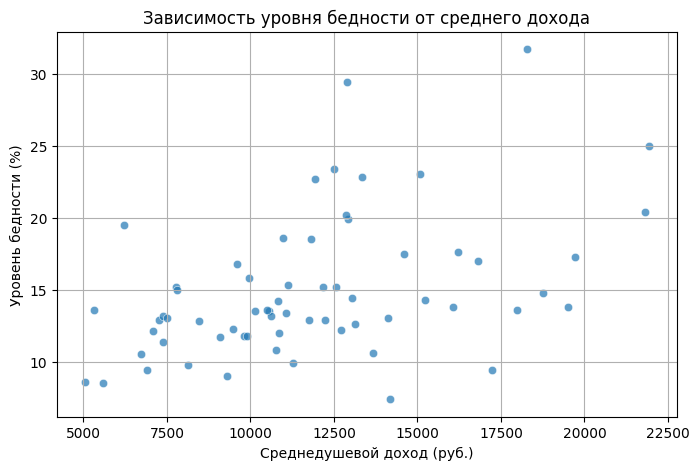

Корреляция между доходом и бедностью: 0.44


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=final_df_clean, x='avg_income', y='poverty_percent', alpha=0.7)
plt.title('Зависимость уровня бедности от среднего дохода')
plt.xlabel('Среднедушевой доход (руб.)')
plt.ylabel('Уровень бедности (%)')
plt.grid(True)
plt.show()

# Проверим корреляцию
corr = final_df_clean['avg_income'].corr(final_df_clean['poverty_percent'])
print(f"Корреляция между доходом и бедностью: {corr:.2f}")

In [51]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"

# Читаем файл со здравоохранением
health = pd.read_excel(os.path.join(DATA_PATH, "healthcare.xlsx"))

print(f"Размер файла: {health.shape}")
print(f"Доступные годы: {sorted(health['year'].unique())}")

# Ищем показатели, связанные со смертностью и заболеваемостью
keywords = ['смертност', 'заболеваемост', 'продолжительность жизни']
filtered_indicators = health[health['indicator_name'].str.lower().str.contains('|'.join(keywords), na=False)]['indicator_name'].unique()

print(f"\nНайдено уникальных показателей: {len(filtered_indicators)}")
print("\nСписок (первые 30):")
for name in filtered_indicators[:30]:
    print(f" - {name}")

Размер файла: (93976, 14)
Доступные годы: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

Найдено уникальных показателей: 7

Список (первые 30):
 - Смертность населения по основным классам причин смерти
 - Заболеваемость детей в возрасте 0‒14 лет по основным классам болезней
 - Заболеваемость населения
 - Заболеваемость населения отдельными инфекционными болезнями
 - Заболеваемость населения по основным классам болезней
 - Заболеваемость населения социально значимыми болезнями
 - Заболеваемость подростков в возрасте 15‒17 лет по основным классам болезней


In [52]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"
health = pd.read_excel(os.path.join(DATA_PATH, "healthcare.xlsx"))

# 1. Фильтруем нужные показатели
# Важно: "Заболеваемость населения" может быть в нескольких вариациях, 
# поэтому используем точное совпадение
mortality = health[health['indicator_name'] == 'Смертность населения по основным классам причин смерти'].copy()
morbidity = health[health['indicator_name'] == 'Заболеваемость населения'].copy()

# 2. Очищаем названия регионов от пробелов
for df in [mortality, morbidity]:
    df['object_name'] = df['object_name'].str.strip()

# 3. Берем только 2020 год и нужные столбцы
mortality_2020 = mortality[mortality['year'] == 2020][['object_name', 'indicator_value']]
morbidity_2020 = morbidity[morbidity['year'] == 2020][['object_name', 'indicator_value']]

# Переименовываем столбцы
mortality_2020 = mortality_2020.rename(columns={'object_name': 'region', 'indicator_value': 'mortality_rate'})
morbidity_2020 = morbidity_2020.rename(columns={'object_name': 'region', 'indicator_value': 'morbidity_rate'})

# 4. Убираем возможные дубликаты (в смертности часто есть разбивка по классам болезней)
mortality_2020 = mortality_2020.drop_duplicates(subset=['region'], keep='first')
morbidity_2020 = morbidity_2020.drop_duplicates(subset=['region'], keep='first')

# 5. Объединяем с нашим основным датасетом (final_df_clean)
final_df_health = final_df_clean.merge(mortality_2020, on='region', how='left')
final_df_health = final_df_health.merge(morbidity_2020, on='region', how='left')

print(f"Итоговый размер датасета: {final_df_health.shape}")
print("\nПервые 5 строк:")
display(final_df_health.head())

Итоговый размер датасета: (64, 8)

Первые 5 строк:


,region,poverty_percent,avg_income,children_pct,pensioners_pct,working_age_pct,mortality_rate,morbidity_rate
0,Российская Федерация,12.2,12720.2,39.8,6.0,54.2,NaN,753.5
1,Брянская область,13.6,5311.4,43.9,4.6,51.5,NaN,770.0
2,Воронежская область,8.5,5572.6,38.7,5.0,56.3,NaN,529.0
3,Костромская область,11.8,9809.1,42.4,6.7,50.9,NaN,748.1
4,Курская область,9.9,11276.6,33.2,7.5,59.3,NaN,499.9


In [53]:
# Ищем все уникальные названия показателей, где есть слово "смертность"
mortality_names = health[health['indicator_name'].str.lower().str.contains('смертност', na=False)]['indicator_name'].unique()
for name in mortality_names:
    print(f" - {name}")

 - Смертность населения по основным классам причин смерти


In [54]:
# Смотрим, за какие годы есть данные по смертности
mort_all = health[health['indicator_name'] == 'Смертность населения по основным классам причин смерти']
print("Доступные годы для смертности:", sorted(mort_all['year'].unique()))

# И посмотрим на любые данные (например, за 2019)
print("\nПример данных (если есть):")
display(mort_all[['object_name', 'year', 'indicator_value']].head())

Доступные годы для смертности: [2022]

Пример данных (если есть):


,object_name,year,indicator_value
576,Алтайский край,2022,83.8
577,Амурская область,2022,118.6
578,Архангельская область (без автономного округа),2022,68.9
579,Архангельская область (с автономным округом),2022,69.9
580,Астраханская область,2022,50.0


In [55]:
# 1. Берем смертность за 2022 год
mortality_2022 = health[
    (health['indicator_name'] == 'Смертность населения по основным классам причин смерти') & 
    (health['year'] == 2022)
].copy()

# 2. Убираем пробелы в названиях регионов
mortality_2022['object_name'] = mortality_2022['object_name'].str.strip()

# 3. Оставляем нужные столбцы и переименовываем
mortality_2022 = mortality_2022[['object_name', 'indicator_value']]
mortality_2022 = mortality_2022.rename(columns={
    'object_name': 'region',
    'indicator_value': 'mortality_rate'
})

# 4. Убираем дубликаты (на всякий случай)
mortality_2022 = mortality_2022.drop_duplicates(subset=['region'], keep='first')

# 5. Джойним к нашему основному датафрейму (final_df_clean)
final_df_health = final_df_clean.merge(mortality_2022, on='region', how='left')

print(f"Итоговый размер: {final_df_health.shape}")
print(f"Пропуски в смертности: {final_df_health['mortality_rate'].isna().sum()}")
display(final_df_health.head())

Итоговый размер: (64, 7)
Пропуски в смертности: 0


,region,poverty_percent,avg_income,children_pct,pensioners_pct,working_age_pct,mortality_rate
0,Российская Федерация,12.2,12720.2,39.8,6.0,54.2,55.6
1,Брянская область,13.6,5311.4,43.9,4.6,51.5,89.3
2,Воронежская область,8.5,5572.6,38.7,5.0,56.3,33.8
3,Костромская область,11.8,9809.1,42.4,6.7,50.9,67.1
4,Курская область,9.9,11276.6,33.2,7.5,59.3,148.2


In [56]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Убираем "Российскую Федерацию" (это агрегат по всей стране, а не регион)
df_cluster = final_df_health[final_df_health['region'] != 'Российская Федерация'].copy()

# 2. Заполняем оставшиеся пропуски (если есть) средними значениями
df_cluster = df_cluster.fillna(df_cluster.mean(numeric_only=True))

# 3. Выбираем признаки для кластеризации
features = ['poverty_percent', 'avg_income', 'children_pct', 'pensioners_pct', 'working_age_pct', 'mortality_rate']
X = df_cluster[features]

# 4. Масштабируем данные
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Данные для кластеризации готовы. Размер: {X_scaled.shape}")
print(f"Среднее значение после масштабирования (должно быть ~0): {X_scaled.mean():.2f}")

Данные для кластеризации готовы. Размер: (63, 6)
Среднее значение после масштабирования (должно быть ~0): 0.00


Распределение регионов по кластерам:
0    21
1    19
2     9
3    14
Name: cluster, dtype: int64

Профиль кластеров (средние значения):


,poverty_percent,avg_income,children_pct,pensioners_pct,working_age_pct,mortality_rate
cluster,,,,,,
0,13.58,11160.86,39.74,3.76,56.50,62.98
1,14.09,10512.06,39.99,7.37,52.65,78.26
2,23.06,16792.64,41.59,6.34,52.04,38.27
3,13.04,11393.51,33.53,7.38,59.10,74.54


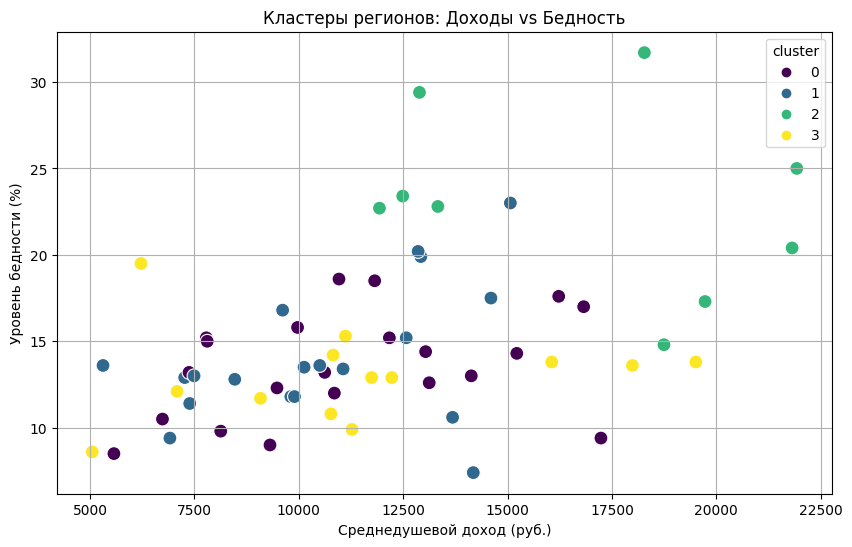

In [57]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Обучаем K-Means на 4 кластера
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cluster['cluster'] = kmeans.fit_predict(X_scaled)

# 2. Смотрим, сколько регионов в каждом кластере
print("Распределение регионов по кластерам:")
print(df_cluster['cluster'].value_counts().sort_index())

# 3. Смотрим средние значения признаков по кластерам, чтобы понять их "профиль"
cluster_profile = df_cluster.groupby('cluster')[features].mean().round(2)
print("\nПрофиль кластеров (средние значения):")
display(cluster_profile)

# 4. Визуализация: Бедность vs Доходы с окраской по кластерам
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_cluster, 
    x='avg_income', 
    y='poverty_percent', 
    hue='cluster', 
    palette='viridis', 
    s=100
)
plt.title('Кластеры регионов: Доходы vs Бедность')
plt.xlabel('Среднедушевой доход (руб.)')
plt.ylabel('Уровень бедности (%)')
plt.grid(True)
plt.show()

In [58]:
# Смотрим регионы из самого проблемного кластера (1)
print("Регионы Кластера 1 (низкие доходы, высокая смертность):")
display(df_cluster[df_cluster['cluster'] == 1][['region', 'poverty_percent', 'avg_income', 'mortality_rate']])

# Смотрим регионы из кластера с самой высокой бедностью (2)
print("\nРегионы Кластера 2 (высокая бедность):")
display(df_cluster[df_cluster['cluster'] == 2][['region', 'poverty_percent', 'avg_income', 'mortality_rate']])

Регионы Кластера 1 (низкие доходы, высокая смертность):


,region,poverty_percent,avg_income,mortality_rate
1,Брянская область,13.6,5311.4,89.3
3,Костромская область,11.8,9809.1,67.1
6,Московская область,7.4,14178.6,43.5
8,Рязанская область,12.9,7267.6,122.8
11,Тверская область,11.4,7387.6,80.3
16,Вологодская область,12.8,8466.6,61.3
17,Калининградская область,13.5,10127.0,58.7
22,Республика Крым,17.5,14601.9,107.1
23,Краснодарский край,10.6,13683.0,42.0
33,Республика Башкортостан,11.8,9896.7,86.9



Регионы Кластера 2 (высокая бедность):


,region,poverty_percent,avg_income,mortality_rate
21,Республика Калмыкия,22.7,11931.6,33.9
27,Республика Дагестан,14.8,18745.0,46.8
28,Республика Ингушетия,29.4,12890.2,6.6
29,Кабардино-Балкарская Республика,25.0,21926.1,51.3
30,Карачаево-Черкесская Республика,23.4,12489.4,24.3
31,Чеченская Республика,20.4,21814.7,26.1
47,Республика Алтай,22.8,13330.9,62.6
48,Республика Тыва,31.7,18276.0,51.1
58,Республика Саха (Якутия),17.3,19729.9,41.7


In [59]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"
services = pd.read_excel(os.path.join(DATA_PATH, "paid_service.xlsx"))

# Ищем показатели про объем услуг на душу населения
keywords = ['объем', 'услуг', 'душу']
filtered = services[services['indicator_name'].str.lower().str.contains('|'.join(keywords), na=False)]['indicator_name'].unique()

for name in filtered[:15]:
    print(f" - {name}")

 - Индексы потребительских цен на бытовые услуги
 - Индексы физического объема платных бытовых услуг населению
 - Объем платных бытовых услуг населению
 - Показатели платных ритуальных услуг
 - Показатели платных услуг каршеринга
 - Показатели платных услуг парикмахерских и косметических
 - Показатели платных услуг по изготовлению и ремонту мебели
 - Показатели платных услуг по ремонту и пошиву швейных, меховых и кожаных изделий, головных уборов и изделий текстильной галантереи, ремонту, пошиву и вязанию трикотажных изделий
 - Показатели платных услуг по ремонту и строительству жилья и других построек
 - Показатели платных услуг по ремонту и техническому обслуживанию бытовой радиоэлектронной аппаратуры, бытовых машин и приборов, ремонту и изготовлению металлоизделий
 - Показатели платных услуг по ремонту, окраске и пошиву обуви
 - Показатели платных услуг по техническому обслуживанию и ремонту транспортных средств, машин и оборудования
 - Показатели платных услуг по химической чистке и

In [60]:
# Ищем общий объем платных услуг (без слова "бытовые")
general_services = services[
    (services['indicator_name'].str.lower().str.contains('объем', na=False)) & 
    (services['indicator_name'].str.lower().str.contains('услуг', na=False)) &
    (~services['indicator_name'].str.lower().str.contains('бытов', na=False))
]['indicator_name'].unique()

print("Общие показатели по услугам:")
for name in general_services[:10]:
    print(f" - {name}")

Общие показатели по услугам:
 - Индексы физического объема жилищных услуг населению
 - Объем жилищных услуг населению
 - Индексы физического объема коммунальных услуг населению
 - Объем коммунальных услуг населению
 - Индексы физического объема платных медицинских услуг населению
 - Объем платных медицинских услуг населению
 - Индексы физического объема платных услуг населению
 - Объем платных услуг населению
 - Индексы физического объема транспортных услуг населению
 - Объем транспортных услуг населению


In [61]:
DATA_PATH = r"D:\rfm-project\vulnerable-groups-project\data\raw"
services = pd.read_excel(os.path.join(DATA_PATH, "paid_service.xlsx"))

# 1. Фильтруем по нужному показателю и 2020 году
services_2020 = services[
    (services['indicator_name'] == 'Объем платных услуг населению') & 
    (services['year'] == 2020)
].copy()

# 2. Очищаем названия регионов от пробелов
services_2020['object_name'] = services_2020['object_name'].str.strip()

# 3. Оставляем нужные столбцы и переименовываем
services_2020 = services_2020[['object_name', 'indicator_value']]
services_2020 = services_2020.rename(columns={
    'object_name': 'region',
    'indicator_value': 'services_volume'
})

# 4. Убираем дубликаты
services_2020 = services_2020.drop_duplicates(subset=['region'], keep='first')

# 5. Джойним к нашему основному датафрейму
final_df_full = final_df_health.merge(services_2020, on='region', how='left')

print(f"Итоговый размер: {final_df_full.shape}")
print(f"Пропуски в объеме услуг: {final_df_full['services_volume'].isna().sum()}")
display(final_df_full.head())

Итоговый размер: (64, 8)
Пропуски в объеме услуг: 0


,region,poverty_percent,avg_income,children_pct,pensioners_pct,working_age_pct,mortality_rate,services_volume
0,Российская Федерация,12.2,12720.2,39.8,6.0,54.2,55.6,9.294198e+06
1,Брянская область,13.6,5311.4,43.9,4.6,51.5,89.3,5.284356e+04
2,Воронежская область,8.5,5572.6,38.7,5.0,56.3,33.8,1.163273e+05
3,Костромская область,11.8,9809.1,42.4,6.7,50.9,67.1,2.680962e+04
4,Курская область,9.9,11276.6,33.2,7.5,59.3,148.2,5.299750e+04


Матрица корреляций:


,poverty_percent,avg_income,services_mln,mortality_rate
poverty_percent,1.000000,0.441607,-0.110825,-0.046164
avg_income,0.441607,1.000000,0.029772,-0.179652
services_mln,-0.110825,0.029772,1.000000,-0.067540
mortality_rate,-0.046164,-0.179652,-0.067540,1.000000


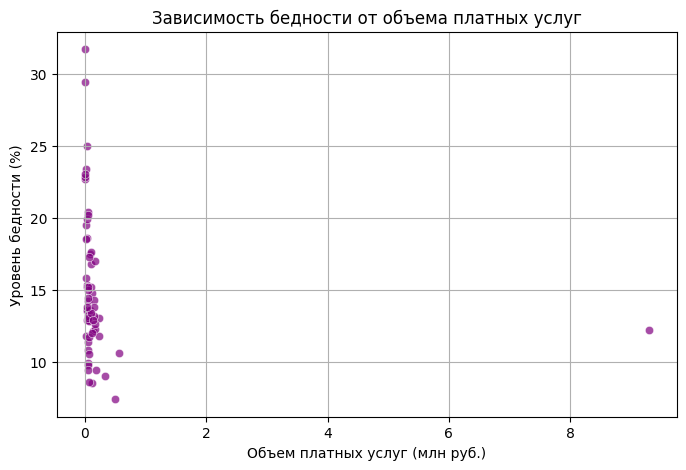

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Переводим объем услуг в миллионы рублей для удобства
final_df_full['services_mln'] = final_df_full['services_volume'] / 1_000_000

# 2. Считаем корреляцию
corr_matrix = final_df_full[['poverty_percent', 'avg_income', 'services_mln', 'mortality_rate']].corr()

print("Матрица корреляций:")
display(corr_matrix)

# 3. Визуализация: Бедность vs Объем услуг
plt.figure(figsize=(8, 5))
sns.scatterplot(data=final_df_full, x='services_mln', y='poverty_percent', alpha=0.7, color='purple')
plt.title('Зависимость бедности от объема платных услуг')
plt.xlabel('Объем платных услуг (млн руб.)')
plt.ylabel('Уровень бедности (%)')
plt.grid(True)
plt.show()

Регион-гигант по услугам: Российская Федерация (9.29 млн руб.)


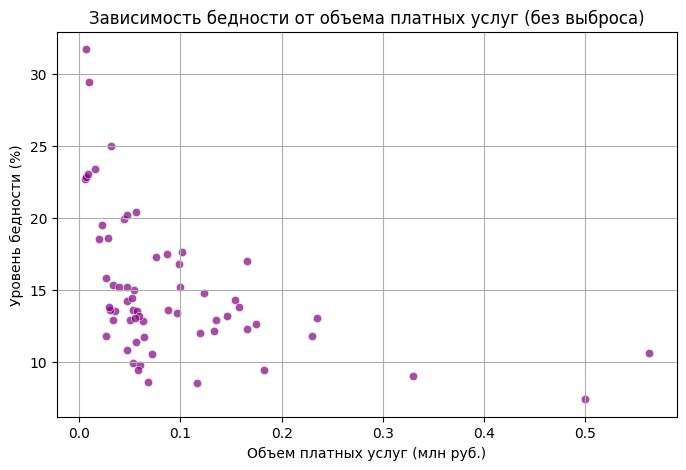

Корреляция (без выброса): -0.45


In [63]:
# 1. Найдем регион с аномально высоким объемом услуг
top_region = final_df_full.loc[final_df_full['services_mln'].idxmax()]
print(f"Регион-гигант по услугам: {top_region['region']} ({top_region['services_mln']:.2f} млн руб.)")

# 2. Уберем его для графика
df_no_outlier = final_df_full[final_df_full['region'] != top_region['region']]

# 3. Строим график заново
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_no_outlier, x='services_mln', y='poverty_percent', alpha=0.7, color='purple')
plt.title('Зависимость бедности от объема платных услуг (без выброса)')
plt.xlabel('Объем платных услуг (млн руб.)')
plt.ylabel('Уровень бедности (%)')
plt.grid(True)
plt.show()

# 4. Считаем корреляцию без выброса
corr_no_outlier = df_no_outlier['services_mln'].corr(df_no_outlier['poverty_percent'])
print(f"Корреляция (без выброса): {corr_no_outlier:.2f}")

In [64]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Убираем агрегат "Российская Федерация"
df_final_cluster = final_df_full[final_df_full['region'] != 'Российская Федерация'].copy()

# 2. Выбираем признаки для кластеризации (уже с услугами)
features_v2 = ['poverty_percent', 'avg_income', 'children_pct', 'pensioners_pct', 'mortality_rate', 'services_mln']
X_v2 = df_final_cluster[features_v2]

# 3. Масштабируем
scaler_v2 = StandardScaler()
X_scaled_v2 = scaler_v2.fit_transform(X_v2)

# 4. Обучаем K-Means (4 кластера)
kmeans_v2 = KMeans(n_clusters=4, random_state=42, n_init=10)
df_final_cluster['cluster'] = kmeans_v2.fit_predict(X_scaled_v2)

# 5. Смотрим на профили новых кластеров
cluster_profile_v2 = df_final_cluster.groupby('cluster')[features_v2].mean().round(2)
print("Новые профили кластеров:")
display(cluster_profile_v2)

Новые профили кластеров:


,poverty_percent,avg_income,children_pct,pensioners_pct,mortality_rate,services_mln
cluster,,,,,,
0,20.83,15182.79,41.52,5.16,55.96,0.05
1,9.00,12390.53,41.47,6.90,40.63,0.46
2,12.83,9884.57,39.95,4.91,65.83,0.10
3,14.63,12007.17,34.41,8.10,79.72,0.05


In [65]:
# Смотрим регионы в каждом кластере
for cluster_id in range(4):
    print(f"\n{'='*40}")
    print(f"КЛАСТЕР {cluster_id}")
    print(f"{'='*40}")
    regions = df_final_cluster[df_final_cluster['cluster'] == cluster_id]['region'].tolist()
    print(", ".join(regions))


КЛАСТЕР 0
Республика Калмыкия, Республика Крым, Республика Дагестан, Республика Ингушетия, Карачаево-Черкесская Республика, Чеченская Республика, Курганская область, Республика Алтай, Республика Тыва, Республика Хакасия, Красноярский край, Иркутская область, Республика Бурятия, Республика Саха (Якутия)

КЛАСТЕР 1
Московская область, Краснодарский край, Свердловская область

КЛАСТЕР 2
Брянская область, Воронежская область, Костромская область, Тверская область, Тульская область, Ярославская область, Мурманская область, Псковская область, Астраханская область, Волгоградская область, Ростовская область, Ставропольский край, Республика Башкортостан, Пермский край, Кировская область, Нижегородская область, Оренбургская область, Пензенская область, Самарская область, Саратовская область, Ульяновская область, Челябинская область, Алтайский край, Омская область, Томская область, Хабаровский край, Амурская область

КЛАСТЕР 3
Курская область, Липецкая область, Орловская область, Рязанская облас

# 🏆 Итоговый отчет по проекту: Определение уязвимых групп населения

## 🎯 Цель проекта
Кластеризовать регионы России и определить, какие из них наиболее остро нуждаются в помощи малообеспеченным слоям населения. Выявить факторы, влияющие на уровень бедности.

## 📊 Используемые данные
Для анализа были объединены данные из нескольких источников:
1. Уровень бедности по регионам (Росстат).
2. Распределение малоимущего населения (Росстат).
3. Среднедушевые доходы (база «Если быть точным»).
4. Смертность населения (база «Если быть точным»).
5. Объем платных услуг на душу населения (Росстат).

---

## 📈 Анализ гипотез (EDA)

### 1. Влияние демографии (дети и пенсионеры) на бедность
Анализ корреляции показал, что связь между уровнем бедности и долей детей/пенсионеров в регионе **крайне слабая**:
* Корреляция с долей детей: **-0.13** (почти нет связи).
* Корреляция с долей пенсионеров: **+0.11** (почти нет связи).

**Вывод:** Сами по себе демографические пропорции (много детей или много стариков) **не являются главной причиной бедности**. Проблема кроется в экономических факторах региона.

### 2. Связь доходов и бедности (Парадокс)
Мы обнаружили **парадоксальную картину**: классическая корреляция между доходами и бедностью составила **0.44** (положительная). 
**Почему так?** Это связано с «северным парадоксом». В таких регионах, как Чукотка, Якутия или Магадан, уровень зарплат очень высок (северные надбавки), но из-за экстремально высоких цен на товары и услуги уровень бедности остается высоким.

### 3. Связь потребления (платных услуг) и бедности
После исключения выброса (агрегата по РФ), корреляция составила **-0.45**.
**Вывод:** Связь **умеренная и обратная**. Чем ниже уровень бедности в регионе, тем выше объем потребляемых услуг (медицина, транспорт, быт). В бедных регионах люди вынуждены экономить на базовых услугах.

---

## 🧩 Результаты кластеризации (K-Means, 4 кластера)

Мы разбили 63 региона на 4 группы по уровню доходов, бедности, смертности и потребления:

### 🟢 Кластер 1 (Благополучные) — 3 региона
*   **Кто:** Московская область, Краснодарский край, Свердловская область.
*   **Профиль:** Самая низкая бедность (9%), высокий объем потребления услуг, низкая смертность. В помощи не нуждаются.

### 🟡 Кластер 3 (Стареющие) — 19 регионов
*   **Кто:** Курская, Липецкая, Рязанская, Камчатский край и др.
*   **Профиль:** Низкая доля детей, самая высокая смертность (79.7). Требуется поддержка систем здравоохранения и пенсионеров.

### 🟠 Кластер 2 (Депрессивные) — 27 регионов
*   **Кто:** Брянская, Воронежская, Нижегородская, Омская области и др.
*   **Профиль:** Самые низкие доходы (9884 руб.), высокая смертность. Это «промышленный пояс», нуждающийся в экономической поддержке и создании рабочих мест.

### 🔴 Кластер 0 (Критическая бедность) — 14 регионов
*   **Кто:** Республики Северного Кавказа (Дагестан, Ингушетия, Чечня), Калмыкия, Тыва, Якутия, Красноярский край.
*   **Профиль:** Высокие доходы, но **экстремально высокая бедность** (20.8%) и **низкое потребление услуг**. Это регионы с высокой стоимостью жизни и традиционным укладом. **Требуют адресной социальной помощи.**

---

## ✅ Ответы на вопросы брифа:
1. **Влияет ли число детей/пенсионеров?** Нет, прямой связи нет.
2. **Связана ли бедность с потреблением?** Да, обратная связь (-0.45).
3. **Кто нуждается в помощи?** Регионы Кластера 0 (высокая бедность при высоких доходах) и Кластера 2 (низкие доходы + высокая смертность).